# Online retail sales analysis

**Question:** where does this online gift shop's revenue come from, and when?

**Data:** [Online Retail](https://archive.ics.uci.edu/dataset/352/online+retail) by Daqing Chen, UCI Machine Learning Repository (CC BY 4.0). It holds every sale of a UK-based online gift retailer from 1 Dec 2010 to 9 Dec 2011: 541,909 invoice lines. Many customers are wholesalers.

Steps: load the raw file, check data quality, clean it, build a small SQLite database for the SQL part, explore, chart, and write up findings.

In [1]:
import json, sqlite3
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

ROOT = Path('..')
RAW = ROOT / 'data' / 'raw' / 'Online Retail.xlsx'
DB = ROOT / 'data' / 'retail.db'
pd.set_option('display.float_format', '{:,.2f}'.format)

raw = pd.read_excel(RAW, dtype={'InvoiceNo': str, 'StockCode': str})
print(raw.shape)
raw.head()

(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,"17,850.00",United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,"17,850.00",United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,"17,850.00",United Kingdom


## 1. Data quality checks

In [2]:
checks = {
    'Missing CustomerID': raw.CustomerID.isna().sum(),
    'Missing Description': raw.Description.isna().sum(),
    'Exact duplicate rows': raw.duplicated().sum(),
    'Cancellation rows (invoice starts with C)': raw.InvoiceNo.str.startswith('C').sum(),
    'Quantity <= 0': (raw.Quantity <= 0).sum(),
    'UnitPrice <= 0': (raw.UnitPrice <= 0).sum(),
}
print('Dates:', raw.InvoiceDate.min(), 'to', raw.InvoiceDate.max())
pd.Series(checks, name='rows').to_frame()

Dates: 2010-12-01 08:26:00 to 2011-12-09 12:50:00


,rows
Missing CustomerID,135080
Missing Description,1454
Exact duplicate rows,5268
Cancellation rows (invoice starts with C),9288
Quantity <= 0,10624
UnitPrice <= 0,2517


In [3]:
# Stock codes that are not products: postage, fees, discounts, manual adjustments, gift vouchers.
odd = raw[~raw.StockCode.str.match(r'^\d{5}')]
odd.groupby('StockCode').agg(description=('Description', 'first'), rows=('InvoiceNo', 'size')).sort_values('rows', ascending=False).head(15)

,description,rows
StockCode,,
POST,POSTAGE,1256
DOT,DOTCOM POSTAGE,710
M,Manual,571
C2,CARRIAGE,144
D,Discount,77
S,SAMPLES,63
BANK CHARGES,Bank Charges,37
AMAZONFEE,AMAZON FEE,34
CRUK,CRUK Commission,16


In [4]:
# The two biggest lines in the file were cancelled straight away.
raw.loc[raw.Quantity.abs().nlargest(4).index, ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'UnitPrice', 'CustomerID', 'InvoiceDate']]

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,InvoiceDate
540421,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,"16,446.00",2011-12-09 09:15:00
540422,C581484,23843,"PAPER CRAFT , LITTLE BIRDIE",-80995,2.08,"16,446.00",2011-12-09 09:27:00
61619,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,"12,346.00",2011-01-18 10:01:00
61624,C541433,23166,MEDIUM CERAMIC TOP STORAGE JAR,-74215,1.04,"12,346.00",2011-01-18 10:17:00


## 2. Cleaning

1. Drop exact duplicate rows.
2. Drop rows with no CustomerID (about a quarter of rows). Customer-level analysis needs the ID, so every number below is for identified customers.
3. Drop cancellation rows, **and** drop the purchase each cancellation undid. Without this, the 80,995-unit order above would still count as £168k of sales. One £38,970 order was reversed through a 'Manual' line, so it is dropped by invoice number.
4. Drop non-product codes (postage, fees, discounts, manual adjustments, samples, vouchers).
5. Keep only rows with Quantity > 0 and UnitPrice > 0.
6. Add `Revenue = Quantity × UnitPrice` and tidy the text columns.

In [5]:
steps = [('Raw rows', len(raw))]
df = raw.drop_duplicates()
steps.append(('After dropping duplicates', len(df)))

df = df[df.CustomerID.notna()].copy()
df['CustomerID'] = df.CustomerID.astype(int)
steps.append(('After dropping missing CustomerID', len(df)))

is_cancel = df.InvoiceNo.str.startswith('C')
cancels, df = df[is_cancel], df[~is_cancel].copy()
steps.append(('After dropping cancellation rows', len(df)))

# Match each cancellation to one earlier purchase of the same item, quantity and customer, then drop that purchase.
# ponytail: one-to-one match in date order; partial cancellations (smaller quantity) are not matched.
key = ['CustomerID', 'StockCode', 'Quantity']
undone = cancels.assign(Quantity=-cancels.Quantity)[key]
undone = undone.assign(n=undone.groupby(key).cumcount(), cancelled=True)
df = df.sort_values('InvoiceDate')
df['n'] = df.groupby(key).cumcount()
df = df.merge(undone, on=key + ['n'], how='left')
df = df[df.cancelled.isna()].drop(columns=['n', 'cancelled'])
# Invoice 556444 (60 wicker picnic baskets, £38,970) was reversed by a 'Manual' line of the same amount
# (C556445), which the item match above cannot see. It is the only such case for a product line.
df = df[~((df.InvoiceNo == '556444') & (df.StockCode == '22502'))]
steps.append(('After dropping purchases that were cancelled', len(df)))

NON_PRODUCT = {'POST', 'D', 'C2', 'M', 'BANK CHARGES', 'AMAZONFEE', 'B', 'CRUK', 'DOT', 'S', 'PADS'}
df = df[~df.StockCode.str.upper().isin(NON_PRODUCT) & ~df.StockCode.str.startswith('gift_')]
steps.append(('After dropping non-product codes', len(df)))

df = df[(df.Quantity > 0) & (df.UnitPrice > 0)].copy()
steps.append(('After keeping Quantity > 0 and UnitPrice > 0', len(df)))

df['Description'] = df.Description.str.strip()
df['Revenue'] = df.Quantity * df.UnitPrice
cleaning = pd.DataFrame(steps, columns=['step', 'rows'])
cleaning

,step,rows
0,Raw rows,541909
1,After dropping duplicates,536641
2,After dropping missing CustomerID,401604
3,After dropping cancellation rows,392732
4,After dropping purchases that were cancelled,389564
5,After dropping non-product codes,388099
6,After keeping Quantity > 0 and UnitPrice > 0,388066


## 3. SQLite database for the SQL queries

Four tables: `customers`, `products`, `orders`, `order_items`. A few stock codes have more than one description, and 8 customers appear under two countries, so each takes its most common value.

In [6]:
def most_common(frame, key, col):
    counts = frame.groupby([key, col]).size().reset_index(name='n').sort_values('n')
    return counts.drop_duplicates(key, keep='last').drop(columns='n')

customers = most_common(df, 'CustomerID', 'Country').rename(columns={'CustomerID': 'customer_id', 'Country': 'country'})
products = most_common(df, 'StockCode', 'Description').rename(columns={'StockCode': 'stock_code', 'Description': 'description'})
orders = (df.groupby('InvoiceNo').agg(customer_id=('CustomerID', 'first'), invoice_date=('InvoiceDate', 'min'))
            .reset_index().rename(columns={'InvoiceNo': 'invoice_no'}))
orders['invoice_date'] = orders.invoice_date.dt.strftime('%Y-%m-%d %H:%M:%S')
items = df[['InvoiceNo', 'StockCode', 'Quantity', 'UnitPrice']].set_axis(['invoice_no', 'stock_code', 'quantity', 'unit_price'], axis=1)

SCHEMA = '''
CREATE TABLE customers (customer_id INTEGER PRIMARY KEY, country TEXT NOT NULL);
CREATE TABLE products (stock_code TEXT PRIMARY KEY, description TEXT NOT NULL);
CREATE TABLE orders (invoice_no TEXT PRIMARY KEY, customer_id INTEGER NOT NULL REFERENCES customers, invoice_date TEXT NOT NULL);
CREATE TABLE order_items (invoice_no TEXT NOT NULL REFERENCES orders, stock_code TEXT NOT NULL REFERENCES products,
                          quantity INTEGER NOT NULL CHECK (quantity > 0), unit_price REAL NOT NULL CHECK (unit_price > 0));
CREATE INDEX idx_items_invoice ON order_items (invoice_no);
CREATE INDEX idx_orders_customer ON orders (customer_id);
'''
DB.unlink(missing_ok=True)
with sqlite3.connect(DB) as con:
    con.executescript(SCHEMA)
    for name, table in [('customers', customers), ('products', products), ('orders', orders), ('order_items', items)]:
        table.to_sql(name, con, if_exists='append', index=False)
    print({t: con.execute(f'SELECT COUNT(*) FROM {t}').fetchone()[0] for t in ['customers', 'products', 'orders', 'order_items']})

{'customers': 4322, 'products': 3644, 'orders': 18264, 'order_items': 388066}


## 4. Exploration

In [7]:
order_totals = df.groupby('InvoiceNo').Revenue.sum()
kpis = {
    'revenue': round(float(df.Revenue.sum()), 2),
    'orders': int(df.InvoiceNo.nunique()),
    'customers': int(df.CustomerID.nunique()),
    'avg_order_value': round(float(order_totals.mean()), 2),
    'median_order_value': round(float(order_totals.median()), 2),
    'products': int(df.StockCode.nunique()),
    'countries': int(df.Country.nunique()),
}
kpis

{'revenue': 8303718.5,
 'orders': 18264,
 'customers': 4322,
 'avg_order_value': 454.65,
 'median_order_value': 300.49,
 'products': 3644,
 'countries': 37}

In [8]:
df[['Quantity', 'UnitPrice', 'Revenue']].describe(percentiles=[.25, .5, .75, .99])

,Quantity,UnitPrice,Revenue
count,"388,066.00","388,066.00","388,066.00"
mean,12.67,2.85,21.40
std,42.17,3.98,68.40
min,1.00,0.04,0.06
25%,2.00,1.25,4.95
50%,6.00,1.95,11.90
75%,12.00,3.75,19.80
99%,120.00,12.75,199.20
max,"4,800.00",649.50,"7,144.72"


In [9]:
BLUE, INK, MUTED, GRID = '#2a78d6', '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({
    'figure.dpi': 110, 'savefig.dpi': 150, 'font.size': 10, 'axes.titlesize': 12, 'axes.titleweight': 'bold',
    'axes.titlelocation': 'left', 'axes.titlecolor': INK, 'axes.labelcolor': MUTED, 'axes.edgecolor': GRID,
    'xtick.color': MUTED, 'ytick.color': MUTED, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8, 'axes.axisbelow': True,
})
CHARTS = Path('charts'); CHARTS.mkdir(exist_ok=True)
gbp = FuncFormatter(lambda v, _: f'£{v / 1e6:.1f}M' if abs(v) >= 1e6 else f'£{v / 1e3:.0f}k')

def save(fig, name):
    fig.tight_layout()
    fig.savefig(CHARTS / f'{name}.png', bbox_inches='tight')
    plt.show()

### Chart 1: revenue by month
December 2011 is left out of the chart because the data stops on 9 December.

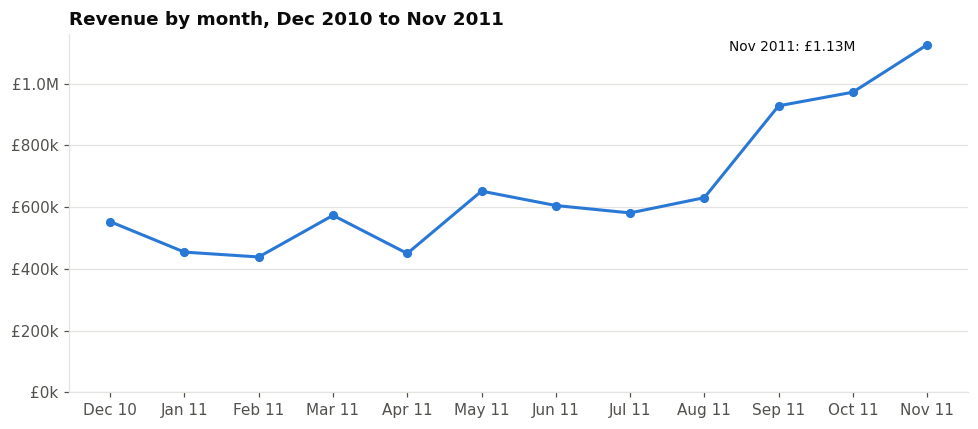

Sep-Nov 2011 = 38% of revenue in these 12 months; Nov is 2.1x the Jan-Aug monthly average


In [10]:
monthly = df.groupby(df.InvoiceDate.dt.to_period('M')).Revenue.sum()
full = monthly[monthly.index < pd.Period('2011-12', 'M')]
fig, ax = plt.subplots(figsize=(9, 4))
x = list(full.index.strftime('%b %y'))
ax.plot(x, full.values, color=BLUE, lw=2, marker='o', ms=5)
peak = full.idxmax()
ax.annotate(f'{peak.strftime("%b %Y")}: £{full.max() / 1e6:.2f}M', (x[full.index.get_loc(peak)], full.max()),
            xytext=(-130, -4), textcoords='offset points', color=INK, fontsize=9)
ax.yaxis.set_major_formatter(gbp); ax.set_ylim(0); ax.grid(axis='x', visible=False)
ax.set_title('Revenue by month, Dec 2010 to Nov 2011')
save(fig, '1_monthly_revenue')
sep_nov = full['2011-09':'2011-11'].sum() / full.sum()
print(f'Sep-Nov 2011 = {sep_nov:.0%} of revenue in these 12 months; Nov is {full.max() / full["2011-01":"2011-08"].mean():.1f}x the Jan-Aug monthly average')

### Chart 2: revenue by country (outside the UK)

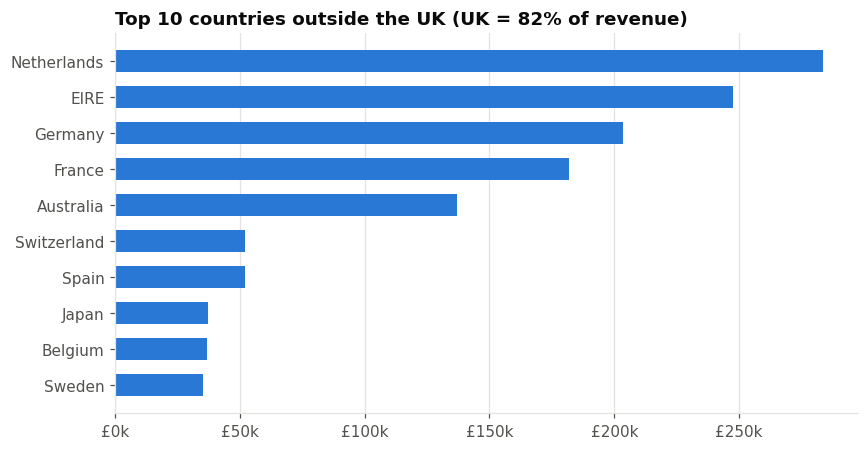

Country
United Kingdom    82.3%
Netherlands        3.4%
EIRE               3.0%
Germany            2.5%
France             2.2%
Australia          1.7%
Name: Revenue, dtype: object

In [11]:
by_country = df.groupby('Country').Revenue.sum().sort_values(ascending=False)
uk_share = by_country['United Kingdom'] / by_country.sum()
top = by_country.drop('United Kingdom').head(10)[::-1]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
ax.xaxis.set_major_formatter(gbp); ax.grid(axis='y', visible=False)
ax.set_title(f'Top 10 countries outside the UK (UK = {uk_share:.0%} of revenue)')
save(fig, '2_countries')
(by_country / by_country.sum()).head(6).map('{:.1%}'.format)

### Chart 3: best-selling products by revenue

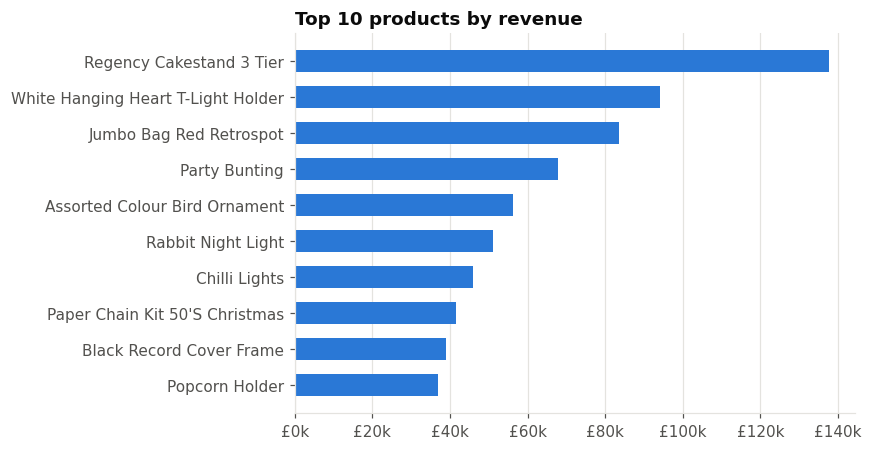

Top 10 products = 7.9% of revenue across 3,644 products


In [12]:
names = products.set_index('stock_code').description
by_product = df.groupby('StockCode').Revenue.sum().nlargest(10)
labels = [names[c].title()[:34] for c in by_product.index]
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(labels[::-1], by_product.values[::-1], color=BLUE, height=0.6)
ax.xaxis.set_major_formatter(gbp); ax.grid(axis='y', visible=False)
ax.set_title('Top 10 products by revenue')
save(fig, '3_products')
print(f'Top 10 products = {by_product.sum() / df.Revenue.sum():.1%} of revenue across {df.StockCode.nunique():,} products')

### Chart 4: when orders are placed

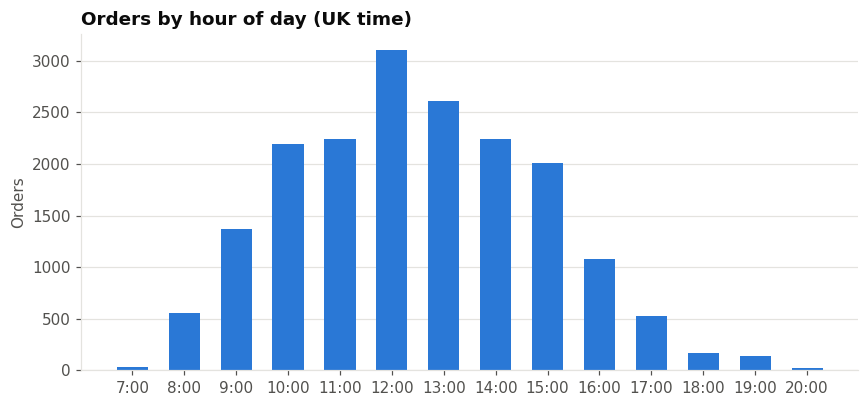

,orders
InvoiceDate,
Monday,2801
Tuesday,3134
Wednesday,3413
Thursday,3976
Friday,2783
Saturday,0
Sunday,2157


In [13]:
by_hour = orders.assign(h=pd.to_datetime(orders.invoice_date).dt.hour).groupby('h').size()
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.bar([f'{h}:00' for h in by_hour.index], by_hour.values, color=BLUE, width=0.6)
ax.grid(axis='x', visible=False); ax.set_ylabel('Orders')
ax.set_title('Orders by hour of day (UK time)')
save(fig, '4_orders_by_hour')
weekday = df.groupby(df.InvoiceDate.dt.day_name()).InvoiceNo.nunique()
weekday.reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']).fillna(0).astype(int).rename('orders').to_frame()

### Chart 5: how concentrated revenue is across customers

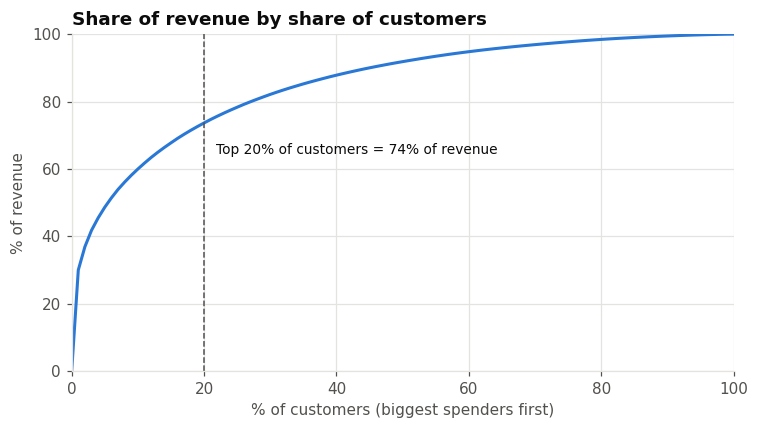

Top 1% = 30% of revenue. One-time buyers = 35% of customers.


In [14]:
spend = df.groupby('CustomerID').Revenue.sum().sort_values(ascending=False)
cum = spend.cumsum() / spend.sum()
pct = list(range(0, 101))
pareto = [0.0] + [float(cum.iloc[max(0, round(len(cum) * p / 100) - 1)]) for p in pct[1:]]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(pct, [v * 100 for v in pareto], color=BLUE, lw=2)
ax.axvline(20, color=MUTED, lw=1, ls='--')
ax.annotate(f'Top 20% of customers = {pareto[20]:.0%} of revenue', (20, pareto[20] * 100), xytext=(8, -20), textcoords='offset points', color=INK, fontsize=9)
ax.set_xlabel('% of customers (biggest spenders first)'); ax.set_ylabel('% of revenue')
ax.set_xlim(0, 100); ax.set_ylim(0, 100)
ax.set_title('Share of revenue by share of customers')
save(fig, '5_customer_concentration')
orders_per_customer = df.groupby('CustomerID').InvoiceNo.nunique()
print(f'Top 1% = {pareto[1]:.0%} of revenue. One-time buyers = {(orders_per_customer == 1).mean():.0%} of customers.')

### Export for the dashboard

In [15]:
def series(s, labels=None):
    return {'labels': list(labels if labels is not None else map(str, s.index)), 'values': [round(float(v), 2) for v in s.values]}

data = {
    'kpis': {**kpis, 'uk_share': round(float(uk_share), 4), 'period': '1 Dec 2010 to 9 Dec 2011'},
    'monthly': series(full, full.index.strftime('%b %Y')),
    'countries': series(top[::-1]),
    'products': series(by_product, [names[c].title() for c in by_product.index]),
    'hours': series(by_hour, [f'{h}:00' for h in by_hour.index]),
    'pareto': {'labels': pct, 'values': [round(v * 100, 1) for v in pareto]},
    'cleaning': steps,
}
(ROOT / 'dashboard' / 'data.json').write_text(json.dumps(data, indent=1, default=int), encoding='utf-8')
print('saved dashboard/data.json')

saved dashboard/data.json


## 5. Findings

1. **The Christmas run-up drives the year.** September to November 2011 brought 38% of the revenue in the 12 full months. November 2011 (£1.13M) was 2.1× the January–August monthly average. *Action:* plan stock and staff from August, and start Christmas promotions in late summer.
2. **A small group of customers carries the business.** The top 20% of customers brought 74% of revenue, and the top 1% (about 43 customers) brought 30%. At the other end, 35% of customers ordered only once. *Action:* give the biggest accounts personal service, and send one-time buyers a reason to order again.
3. **Sales are mostly British, with a few clear next markets.** The UK brought 82% of revenue. The Netherlands, Ireland, Germany and France together brought 11%. *Action:* test growth in those four markets first.

**Other observations**
- 79% of orders were placed between 10:00 and 15:59, and there are no Saturday orders at all. This fits a business that sells mostly to wholesalers during office hours.
- The top 10 products bring only 8% of revenue across 3,644 products, so no single product carries the business.

**Limits**
- Only rows with a CustomerID are used (about a quarter of rows have none), so totals are for identified customers.
- A cancellation is matched to a purchase only when the item, quantity and customer are the same. Partial cancellations stay in the data.
- One year of data, so the seasonal pattern is seen once, not confirmed across years.
